# AP 155 Lab Exercise
---
## Exercise 4
: Derivatives

_Instructions_:
- **Output 1: Finite Difference** Functions and plots of finite-difference methods
- **Output 2: Harmonic Oscillator** Error analysis plot of finite-difference methods.
  
### Student Information
- _Full Name (Last Name, First Name)_: Soriano, Edneil
- _Student No._: 20XX-XXXXX
- _Section_: ANO SECTION NIYO HEHE

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1G9tPPcyMUag91g_R02O0wsGYPiZWy5Nn/view?usp=drive_link) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Problem 1 (You may edit this subsection)

#


![1](my_plot1.png)
# The graph compares the base function against its forward, backward, and central finite-difference derivatives. As the function rises sharply near the origin and then flattens into a constant plateau, all three numerical derivatives accurately capture this initial transition before converging to zero along the baseline.

![1](my_plot2.png)
# The graph s the sigmoidal original function alongside its numerical derivatives. All three finite-difference methods produce nearly identical, bell-shaped curves that correctly peak at the inflection point ($x = 0$) and vanish along the flat plateaus
![1](my_plot3.png)

### Problem 2 (You may edit this subsection)

# The graph illustrates how absolute error varies with step size ($h$) for the three finite-difference methods. Smaller step sizes yield minimal error, while increasing $h$ causes errors to grow and oscillate due to truncation effects and the periodic nature of $\cos(t)$. The central difference method generally maintains lower error at smaller scales, demonstrating superior accuracy before large step sizes break down the approximation. The first two methods have error that scales with O(h) while central difference method scales at O(h^2). This shows that at lower h, h^2 proves t have lower error. It is noticed that higher h does stop the error of the foreward and backward method to be linear. This is because at higher 

EDIT ME. See instruction above for what to include. Insert your discussion here. This is not related to Problem 1. Discuss your key results with ~150 words.




---
## Section 2: Code

### Problem 1: Finite Difference

Let $$f(x) = 1+\frac{1}{2}\tanh(2x)$$

**(a)** Create functions that take as input an array or list of points corresponding to a mathematical function and output the derivative using **(a.1)** forward-difference, **(a.2)** backward-difference, and **(a.3)** central-difference methods.


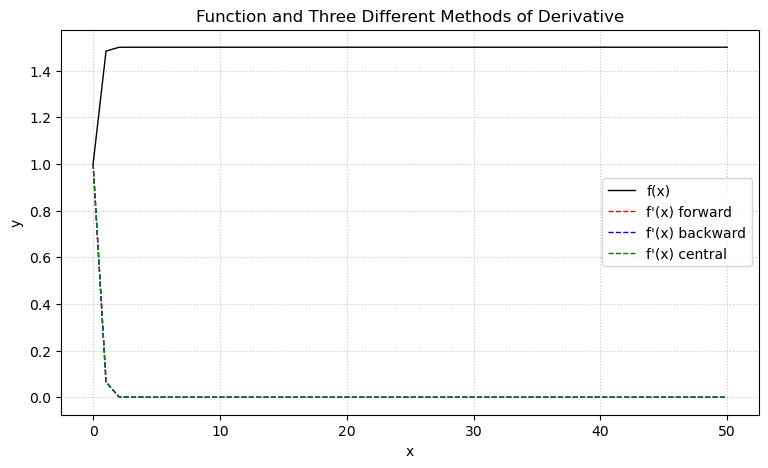

In [2]:
# code here
import numpy as np
import matplotlib.pyplot as plt

Sample = np.linspace(0,50)

def f(x):
  y = 1 + 0.5*np.tanh(2*x)
  return y

def forward(f, x, h=0.001):
  return (f(x+h) - f(x))/h

def backward(f, x, h=0.001):
  return (f(x) - f(x-h))/h

def central(f, x, h=0.001):
  return (f(x+(h/2)) - f(x-(h/2)))/h

xValue = np.linspace(0,50)
Normal = f(xValue)
Forward = forward(f, xValue)
Backward = forward(f, xValue)
Central = forward(f, xValue)

plt.figure(figsize=(9, 5))
plt.plot(xValue, Normal, label="f(x)", color="black", lw=1)
plt.plot(xValue,Forward,label="f'(x) forward",color="red",linestyle="--",lw=1)
plt.plot(xValue,Backward,label="f'(x) backward",color="blue",linestyle="--",lw=1)
plt.plot(xValue,Central,label="f'(x) central",color="green",linestyle="--",lw=1)
plt.title("Function and Three Different Methods of Derivative")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linestyle=":", alpha=0.7)

plt.savefig('my_plot1.png', dpi=150, bbox_inches='tight')
plt.legend()
plt.show()



# The formula for the derivative was directly implemented in the code. It calls the original function and takes the difference of a
# funciton's value at x subtracted some arbitrary small h and at x over the step value.


**(b)** Calculate an analytic formula for the derivative. Make three subplots for the derivative of $f'(x)$, one for each method and the analytic answer on the same plots. Plot the exact answer (use `numpy`) as lines and the numerical one as dots. Describe how the two results compare. Use `plt.subplots`

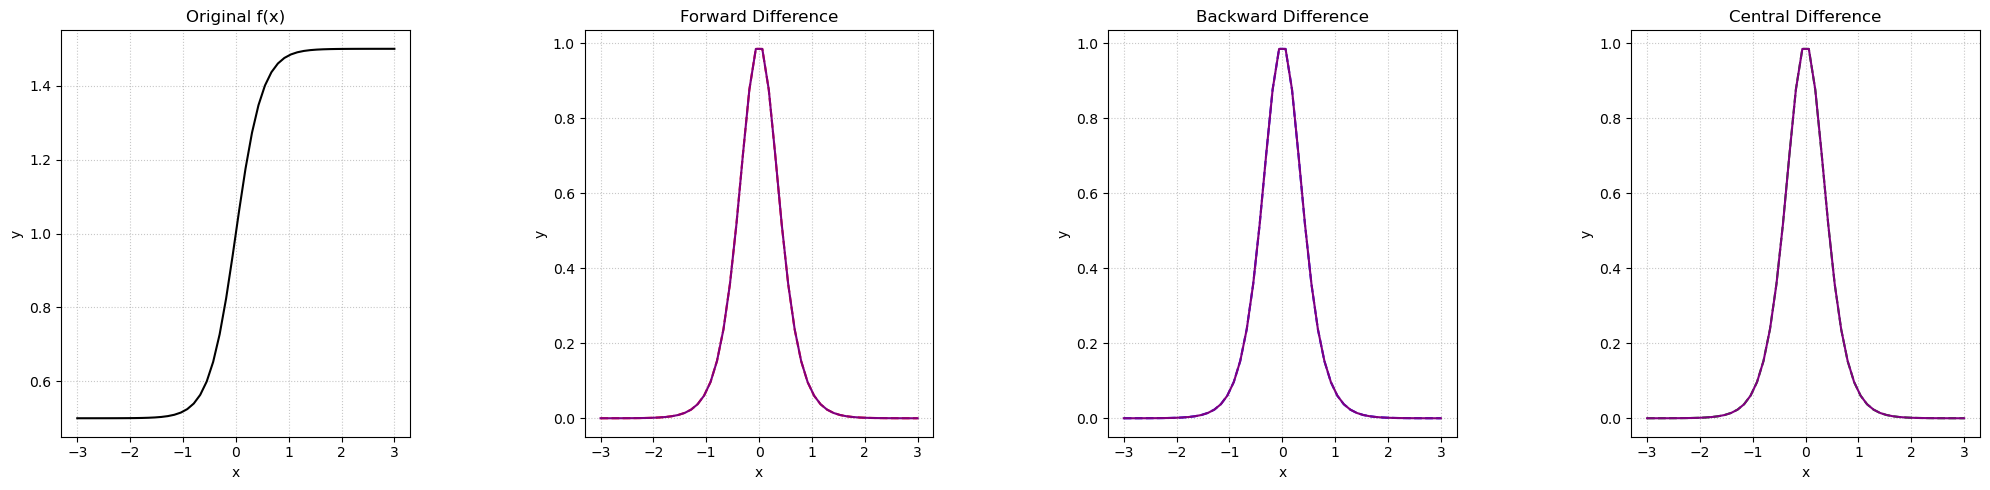

In [3]:

import numpy as np
import matplotlib.pyplot as plt

Sample = np.linspace(0,50)

def f(x):
  y = 1 + 0.5*np.tanh(2*x)
  return y

def forward(f, x, h=0.001):
  return (f(x+h) - f(x))/h

def backward(f, x, h=0.001):
  return (f(x) - f(x-h))/h

def central(f, x, h=0.001):
  return (f(x+(h/2)) - f(x-(h/2)))/h

def analyticD(x):
  return 1 / (np.cosh(2*x)**2)


xValue = np.linspace(-3,3)
Normal = f(xValue)
Forward = forward(f, xValue)
Backward = forward(f, xValue)
Central = forward(f, xValue)
Analytical = analyticD(xValue)

plt.figure(figsize=(20, 5))

# 1. Original Function
plt.subplot(1, 4, 1)
plt.plot(xValue, Normal, color="black", lw=1.5)
plt.title("Original f(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linestyle=":", alpha=0.7)

# Forward Difference
plt.subplot(1, 4, 2)
plt.plot(xValue, Forward, color="red", linestyle="--", lw=1.5)
plt.plot(xValue, Analytical, color="purple", lw=1.5)
plt.title("Forward Difference")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linestyle=":", alpha=0.7)

# Backward Difference
plt.subplot(1, 4, 3)
plt.plot(xValue, Backward, color="blue", linestyle="--", lw=1.5)
plt.plot(xValue, Analytical, color="purple", lw=1.5)
plt.title("Backward Difference")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linestyle=":", alpha=0.7)

# Central Difference
plt.subplot(1, 4, 4)
plt.plot(xValue, Central, color="green", linestyle="--", lw=1.5)
plt.plot(xValue, Analytical, color="purple", lw=1.5)
plt.title("Central Difference")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linestyle=":", alpha=0.7)

plt.tight_layout()


plt.subplots_adjust(wspace=0.5, hspace=0.5)
plt.savefig('my_plot2.png', dpi=300, bbox_inches='tight')
plt.show()

# The analytical derivative was calculated manually and inputted as its own function
# It is compared to the different finite step methods of a derivative



In [258]:
# KOWD HIR

### Problem 2: Simple Harmonic Oscillator

The position $x(t)$ of a 1D simple harmonic oscillator is described by the equation of motion:

$$-kx = \frac{d^2x}{dt^2}$$

We know a solution can take the form of $x(t) = \cos(t)$. Calculate the velocity of this particle using any finite-difference method, and plot its absolute error with respect to the analytical value by varying your step-sizes. The absolute error should have the same trend as the $\mathcal{O}$ error of your chosen method.

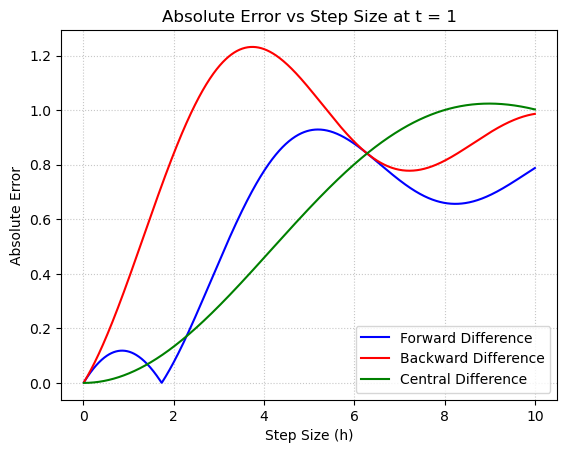

In [1]:
import numpy as np
import matplotlib.pyplot as plt

step = np.linspace(0.01, 10, 1000)

def g(t):
  return np.cos(t)

def analytical(t):
  return -np.sin(t)

def forward(t,h):
  return (g(t+h) - g(t))/h

def backward(t,h):
  return (g(t) - g(t-h))/h

def central(t,h):
  return (g(t+(h/2)) - g(t-(h/2)))/h

def error(a,b):
  return np.abs(a - b)

Wan = []
Too = []
Tree = []

t_chosen = 1

for i in step:
  Output1 = forward(t_chosen, i)
  Error1 = error(Output1, analytical(t_chosen))
  Wan.append(Error1)

for j in step:
  Output2 = backward(t_chosen, j)
  Error2 = error(Output2, analytical(t_chosen))
  Too.append(Error2)

for k in step:
  Output3 = central(t_chosen, k)
  Error3 = error(Output3, analytical(t_chosen))
  Tree.append(Error3)

# Added labels for each finite-difference method
plt.plot(step, Wan, color="blue", lw=1.5, label="Forward Difference")
plt.plot(step, Too, color="red", lw=1.5, label="Backward Difference")
plt.plot(step, Tree, color="green", lw=1.5, label="Central Difference")

plt.title("Absolute Error vs Step Size at t = 1")
plt.xlabel("Step Size (h)")
plt.ylabel("Absolute Error")
plt.legend()  # Renders the labels onto the plot
plt.grid(True, linestyle=":", alpha=0.7)

plt.savefig('my_plot3.png', dpi=300, bbox_inches='tight')
plt.show()

#### Problem 2 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Tutorials

### Derivatives

The derivate of a function $f(x) $ can be approximated using the **forward difference** as

$$f'(x) = \frac{f(x+h) - f(x)}{h} + \mathcal{O}(h)$$

using the **backward difference**

$$f'(x) = \frac{f(x) - f(x-h)}{h} + \mathcal{O}(h)$$

and the **central difference**

$$f'(x) = \frac{f(x + \frac{h}{2}) - f(x - \frac{h}{2})}{h} + \mathcal{O}(h^2)$$

where $h$ is a small step-size. To minimzie error, you can use Richardson Extrapolation, which can be found on the book (Gezerlis).

### Floating-point representation

Python uses 64-bit float by default for any number you type in with a decimal point. Different floating point precision can be used at a lower level, which we can go around by using [Numpy dtypes](https://numpy.org/doc/stable/reference/arrays.dtypes.html).

Useful links:
* [(Goldberg, 1991) *What every computer scientist should know about floating-point arithmetic*](https://dl.acm.org/doi/10.1145/103162.103163)
* [Wikipedia - Floating-point arithmetic](https://en.wikipedia.org/wiki/Floating-point_arithmetic)
* [Data types - NumPy](https://numpy.org/doc/stable/user/basics.types.html)
* [decimal — Decimal fixed-point and floating-point arithmetic](https://docs.python.org/3/library/decimal.html)
* [fractions — Rational numbers](https://docs.python.org/3/library/fractions.html)

In [260]:
import matplotlib.pyplot as plt
import numpy as np

from decimal import Decimal
from fractions import Fraction

# Classic floating point quirks example
print(0.1 + 0.2)

# How about increasing precision?
print(np.float128(0.1) + np.float128(0.2))

# How bad is decreasing precision?
print(np.float16(0.1) + np.float16(0.2))

# Closest we could get to fixed-point arithmetic: decimal
print(Decimal(0.1) + Decimal(0.2))

# How about using an explicit Fraction object type?
print(float(Fraction(1, 10) + Fraction(1, 5)))

0.30000000000000004
0.30000000000000001665
0.2998
0.3000000000000000166533453694
0.3


### Basics

In [261]:
x = 0.5 # floats
y = 1 # integer
z = 'Hello' # string

x, y = y, x # swapping variables
a, b = 2, 3 # multiple assignments
print(x)
print(y)

1
0.5


In [262]:
x + y # sum
x - y # difference
x * y # multiplication
x / y # division
x // y # floor division
x % y # modulo
x ** y # power

1.0

### Control flow

In [263]:
x = 0

if x!= 0:
    print("x is nonzero")
elif x==0:
    print("x is zero")

x is zero


In [264]:
y = 25
if (y%5==0) == True:
    print('y is divisible by 5')

y is divisible by 5


In [265]:
# you can write truthiness conditionals more succinctly as
# if condition is True, mathematically a True equals 1.0 while a False equals 0.0
if not (y%5):
    print('y is divisible by 5')

y is divisible by 5


In [266]:
for i in range(1,15,2):
    print(0.01*i, end=" ") # the end=" " syntax tells the value shall be printed in line

0.01 0.03 0.05 0.07 0.09 0.11 0.13 

### Data structures

In [267]:
xs = []
for i in range(20):
    xs.append(0.1*i)

# BE CAREFUL!!!
# list is different from array
list1 = [1, 2, 3]
list2 = [4, 5, 6]
list1 + list2 # concatenates

[1, 2, 3, 4, 5, 6]

In [268]:
list1 = np.array([1, 2, 3])
list2 = np.array([4, 5, 6])
list1 + list2 # adds element-wise!

array([5, 7, 9])

In [269]:
# Tuples are primarily used to bundle related pieces of data together,
# protect data from accidental modification, and optimize performance.

tuple1 = (1, 2, 3)
tuple1[1]  # can be indexed just like lists

2

In [270]:
# strings can also be indexed like numbers

name = "Wilson"
name[0]

'W'

In [271]:
# string dot format arguments

x, y = 3.1, - 2.5
"{0:1.15f} {1:1.0f}".format(x, y)

# the general string format looks like "{2} {0} {1}".format(a, b, c)
# the number inside the curly brackets contain the index of the variables inside the format( ... )
# you can modify the numbers outputted by specifiying the datatype inside the curly bracket
# {0:1.15f} means print the zeroth number and print the number as a float with 15 decimal places
# {1: 1.0f} means print the 1st number (second actually) and print as a float with 0 decimal places

'3.100000000000000 -2'

In [272]:
# slicing a list creates a new list

xs = [1, 2, 3]
ys = xs[1:] # the square bracket after a list corresponds to index (start:end) ... (start:end:interval)
zs = xs[:] # [:] means copy everything --> create an exact (shallow) copy of xs
print(xs)
print(ys)

# shallow copy duplicates an object's top-level properties
# but keeps references to any nested objects, meaning changes to nested data affect the original.
# A deep copy fully clones all levels and nested structures,
# creating a completely independent duplicate where changes do not affect the original.

[1, 2, 3]
[2, 3]


In [273]:
import copy
from copy import deepcopy

original = [1, 2, [3, 4]] # notice the list inside a list
shallow_copied = original[:]

# modifying a top-level element
shallow_copied[0] = 99
print("After modifying top-level element:")
print(f"Original: {original}")
print(f"Copied:   {shallow_copied}")

# modifying a nested mutable element
shallow_copied[2][0] = "changed"
print("\nAfter modifying nested element (SHALLOW):") # BTW \n in string means paragraph break
print(f"Original: {original}")
print(f"Copied:   {shallow_copied}")

deep_copied = deepcopy(original)
original = [1, 2, [3, 4]]
deep_copied[2][0] = "changed"
print("\nAfter modifying nested element (DEEP COPIED):") # BTW \n in string means paragraph break
print(f"Original: {original}")
print(f"Copied:   {deep_copied}")

After modifying top-level element:
Original: [1, 2, [3, 4]]
Copied:   [99, 2, [3, 4]]

After modifying nested element (SHALLOW):
Original: [1, 2, ['changed', 4]]
Copied:   [99, 2, ['changed', 4]]

After modifying nested element (DEEP COPIED):
Original: [1, 2, [3, 4]]
Copied:   [1, 2, ['changed', 4]]


In [274]:
# dictionaries

htow = {1.41: 31.3, 1.45: 36.7, 1.48: 42.4} # is a dictionary associating heights to weights
# each entry is separated by a comma,
# each entry is composed of keys and items
# the first key is 1.41 with corresponding 31.3 item

for key, item in htow.items():
    print(f'key is {key} with item {item}')

# dictionaries are pretty useful for collecting a parallel set of content
# you can use strings as keys too

key is 1.41 with item 31.3
key is 1.45 with item 36.7
key is 1.48 with item 42.4


### User-defined functions

In [275]:
# start with def<space>name_of_your_function(input, parameters):
# end with return
# once a function encounters return, it ends all operations and sends the value back to the caller

def sumofints(nmax):
    val = sum(range(1,nmax+1))
    return val

# use the above function as
x = sumofints(42)
print(x)

# you could have multiple inputs and outputs
# functions can also return multiple values (effectively the output is a tuple for such cases)

903


In [276]:
from math import cos

def cosder(x, h=0.01): # here h is a default parameter (meaning it already has a preset value)
    return (cos(x+h) - cos(x))/h

#You can call this function with either
cosder(0.)
#or
cosder(0., 0.001)
#ie the 2nd argument is optional

-0.0004999999583255033

In [277]:
# you can also pass functions as inputs
def der(f, x, h=0.01):
    return (f(x+h) - f(x))/h

### List comprehensions

"Using such alternative syntax to make the code more concise and ex-
pressive helps us write new programs, but also makes the lives of future readers easier. Of
course, you do have to exercise your judgement."

In [278]:
def f(x):
    return x//2

xs = [0.1*i for i in range(20)]
ys = [2*x for x in xs] # multiplication operation with a list
ws = [f(x) for x in xs] # evaluating a function with elements of a list
zs = [2*x for x in xs if x>0.3] # pruning a list

### Basic plotting

- We will utilize NumPy and Matplotlib for most of our visualization
    - `import numpy as np` # Docs: https://numpy.org/doc/stable/reference/
    - `import matplotlib.pyplot as plt` # Docs: https://matplotlib.org/stable/api/pyplot_summary.html
  
- We will use Seaborn only to make the defaults look pretty.
- Our focus is to make plotting as flexible as possible.
- Check out its documentation if you're interested with its convenience features.
    - `import seaborn as sns` # Guide: https://seaborn.pydata.org/tutorial/introduction.html
    `sns.set_theme(style="darkgrid")`

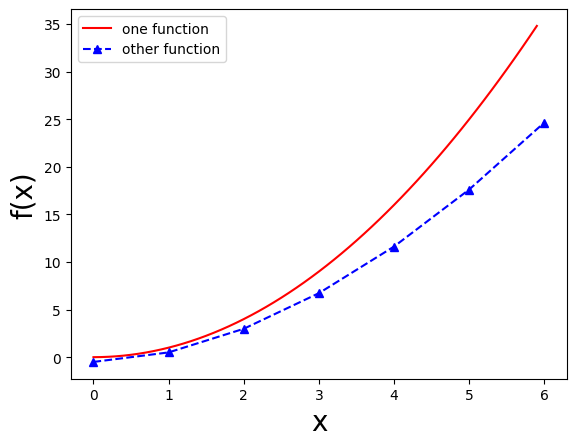

In [279]:
import matplotlib.pyplot as plt

def plotex(cxs,cys,dxs,dys):
    plt.xlabel('x', fontsize=20)
    plt.ylabel('f(x)', fontsize=20)
    plt.plot(cxs, cys, 'r-', label='one function')
    plt.plot(dxs, dys, 'b--^', label='other function')
    plt.legend()
    plt.show()

cxs = [0.1*i for i in range(60)]
cys = [x**2 for x in cxs]
dxs = [i for i in range(7)]
dys = [x**1.8 - 0.5 for x in dxs]

plotex(cxs, cys, dxs, dys)

<ErrorbarContainer object of 3 artists>

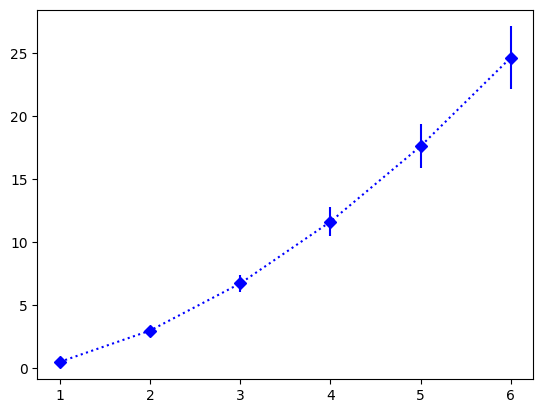

In [280]:
dyerrs = [0.1*y for y in dys]
plt.errorbar(dxs[1:], dys[1:], dyerrs[1:], fmt='b:D', label='with errors')

### NumPy idioms

<img src="figures/gezerlisTable1_2.png" width="67%">

In [281]:
import numpy as np

# for parallel computations: contribs = [w*f(x) for w,x in zip(ws,xs)]

zs = np.array([5, 8], dtype=np.float32) # converts contribs into a NumPy array
A, B, C = np.zeros(5), np.ones(4), np.arange(6)

print(A)
print(B)
print(C)

[0. 0. 0. 0. 0.]
[1. 1. 1. 1.]
[0 1 2 3 4 5]


In [282]:
# you can specify set of points

np.linspace(1, 10, 6) # 6 linearly spaced points from 1 to 10 (including 1 and 10)
np.arange(1, 10, 6) # from 1 to 10 in steps of 6
np.logspace(1, 10, 6) # 6 logarithmically spaced points from 1 to 10

# if you're not sure what to input, you can always shift+Tab inside the parenthesis to check the arguments

array([1.00000000e+01, 6.30957344e+02, 3.98107171e+04, 2.51188643e+06,
       1.58489319e+08, 1.00000000e+10])